<a href="https://colab.research.google.com/github/Tanuja-code125/Applied-ML-Lab/blob/main/ML_Exp9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# To predict whether a person has diabetes based on features such as blood pressure, skin thickness, age, etc., using the bagging ensemble technique. Also perform comparative analysis among the bagging classifier, random forest, and the decision tree classifier.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

In [ ]:
# 1. Load dataset
df = pd.read_csv("/content/dataset_diabetes_exp_9.csv")

In [ ]:
# 2. Separate features and outcome
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

In [ ]:
# 3. Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
# 4. Create three models
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),

    "Bagging Classifier": BaggingClassifier(
        n_estimators=100, random_state=42
    )
}

In [ ]:
# 5. Train and compare models
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    print(name, "Accuracy:",
          round(accuracy_score(y_test, prediction) * 100, 2), "%")

Decision Tree Accuracy: 72.73 %
Random Forest Accuracy: 75.97 %
Bagging Classifier Accuracy: 74.68 %


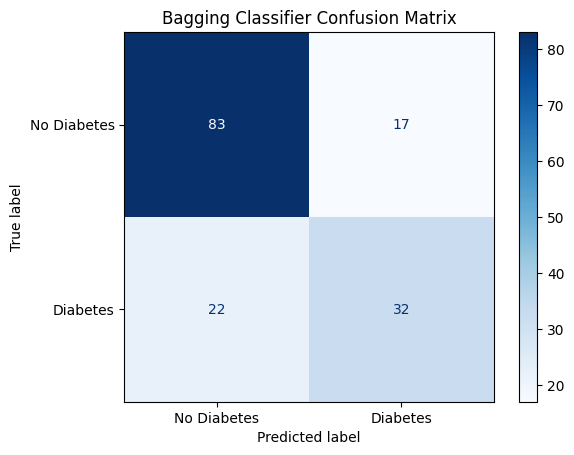

Experiment completed successfully!


In [ ]:
# 6. Show confusion matrix for Bagging
model = models["Bagging Classifier"]
prediction = model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, prediction,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues"
)

plt.title("Bagging Classifier Confusion Matrix")
plt.show()

print("Experiment completed successfully!")